# SupportGen · 05 — Supporting classifiers (queue, priority, type) + inferred sentiment
These components are **predictive, not generative**. They give the support agent structured
information next to the generated reply. We use simple, transparent baselines:

**TF-IDF + linear classifier** (Logistic Regression or Linear SVM)
* TF-IDF turns text into a sparse vector: each word / character n-gram gets a weight that is high
  when it is frequent in this ticket but rare across all tickets.
* A linear model learns one weight per feature per class — fast, strong on text, easy to explain.

They are trained on the **same train split** as the generator, tuned on validation, and reported
**once** on the held-out test split. Because the labels are imbalanced, we report **macro-F1**
(every class counts equally) next to accuracy, and compare against trivial baselines.

**Runtime:** CPU is enough. ~10–20 minutes.

## 0. Setup — Google Drive & project folder
Every SupportGen notebook starts with this same cell. It mounts Google Drive so that all
notebooks share one project folder (`MyDrive/SupportGen`): notebook 01 writes the cleaned
splits there, notebooks 02–06 read them. Nothing ever needs to be uploaded from your laptop.

Set `USE_DRIVE = False` only for a throw-away run — files then live in `/content` and are lost
when the Colab runtime disconnects.

In [1]:
# ── Setup (identical in every SupportGen notebook) ──────────────────────────
USE_DRIVE = True   # False → keep everything in /content (deleted when the runtime ends)

import os, sys
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/SupportGen"
else:
    BASE = "/content/SupportGen"
os.makedirs(BASE, exist_ok=True)
os.environ["SUPPORTGEN_BASE"] = BASE   # read by supportgen_common.py
sys.path.insert(0, BASE)
print("Project folder:", BASE)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/SupportGen


In [2]:
# Colab already ships torch, transformers, accelerate, scikit-learn, pandas, matplotlib.
# These are the extras SupportGen needs (already-installed packages are skipped).
!pip -q install sentencepiece

In [3]:
# Shared helpers were written to Drive by 01_dataset_preparation.ipynb
if not os.path.exists(os.path.join(BASE, "supportgen_common.py")):
    raise FileNotFoundError(
        f"supportgen_common.py not found in {BASE}. Run 01_dataset_preparation.ipynb first "
        "(with the same USE_DRIVE setting).")
import importlib, supportgen_common as sg
importlib.reload(sg)
sg.set_seed()
print("Device:", sg.get_device())

Device: cpu


In [4]:
import json, joblib, sklearn
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

train_df, val_df, test_df = sg.load_split("train"), sg.load_split("val"), sg.load_split("test")
text = lambda d: (d.subject.fillna("") + " . " + d.body).tolist()
TARGETS = ["queue_group", "priority", "type"]
for t in TARGETS:
    print(f"{t}: train label distribution")
    display(train_df[t].value_counts(dropna=False).to_frame("rows").T)

queue_group: train label distribution


queue_group,Technical Support,Product Support,Customer Service,IT Support,Billing and Payments,Returns and Exchanges,Service Outages and Maintenance,Sales and Pre-Sales,Human Resources,General Inquiry
rows,5467,3498,2815,2269,1932,923,741,577,363,263


priority: train label distribution


priority,medium,high,low
rows,7786,7232,3830


type: train label distribution


type,Incident,Request,Problem,Change
rows,7514,5425,3935,1974


## 1. Model selection on the validation split
For each target we try both classifiers with several regularisation strengths `C`
and `class_weight="balanced"` (rare classes get a larger weight in the loss, countering imbalance).
The combination with the best **validation macro-F1** is selected.

In [5]:
def features():
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=100_000, sublinear_tf=True)),
    ])

CANDIDATES = {
    "logreg": lambda C: LogisticRegression(C=C, max_iter=3000, class_weight="balanced"),
    "linear_svm": lambda C: LinearSVC(C=C, class_weight="balanced"),
}
C_GRID = [0.1, 0.5, 1.0, 4.0]

selection = {}
for target in TARGETS:
    tr, va = train_df.dropna(subset=[target]), val_df.dropna(subset=[target])
    feats = features().fit(text(tr))                 # fit vocabulary once per target (train only)
    Xtr, Xva = feats.transform(text(tr)), feats.transform(text(va))
    rows = []
    for name, make in CANDIDATES.items():
        for C in C_GRID:
            clf = make(C).fit(Xtr, tr[target])
            rows.append({"model": name, "C": C, "val_macro_f1": f1_score(va[target], clf.predict(Xva), average="macro")})
    res = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False)
    selection[target] = res.iloc[0].to_dict()
    print(f"\n{target}: best = {selection[target]}")
    display(res.head(4))


queue_group: best = {'model': 'linear_svm', 'C': 4.0, 'val_macro_f1': 0.6662458782289062}


,model,C,val_macro_f1
7,linear_svm,4.0,0.666246
6,linear_svm,1.0,0.649996
5,linear_svm,0.5,0.614075
3,logreg,4.0,0.587247



priority: best = {'model': 'linear_svm', 'C': 4.0, 'val_macro_f1': 0.6766244084648516}


,model,C,val_macro_f1
7,linear_svm,4.0,0.676624
6,linear_svm,1.0,0.657895
5,linear_svm,0.5,0.640946
3,logreg,4.0,0.637380



type: best = {'model': 'linear_svm', 'C': 4.0, 'val_macro_f1': 0.8843814855102078}


,model,C,val_macro_f1
7,linear_svm,4.0,0.884381
6,linear_svm,1.0,0.879864
5,linear_svm,0.5,0.870943
3,logreg,4.0,0.868551


## 2. Final models → held-out test set
The selected configuration is refit on the training split. A Linear SVM has no probabilities, so it is
wrapped in `CalibratedClassifierCV` — the web app can then show a confidence score. Reported test
metrics are for **exactly the pipeline that is saved and deployed**.

Trivial baselines for context:
* **majority** — always predicts the most common class (shows why accuracy alone is misleading),
* **stratified random** — guesses following the training label distribution.

QUEUE_GROUP  (linear_svm, C=4.0)
                                 precision    recall  f1-score   support

           Billing and Payments       0.89      0.82      0.85       216
               Customer Service       0.61      0.50      0.55       356
                General Inquiry       1.00      0.29      0.45        45
                Human Resources       0.95      0.43      0.60        46
                     IT Support       0.72      0.40      0.51       276
                Product Support       0.63      0.55      0.59       467
          Returns and Exchanges       0.90      0.38      0.53       119
            Sales and Pre-Sales       0.91      0.31      0.47        67
Service Outages and Maintenance       0.95      0.61      0.74        94
              Technical Support       0.51      0.87      0.65       653

                       accuracy                           0.62      2339
                      macro avg       0.81      0.52      0.59      2339
                

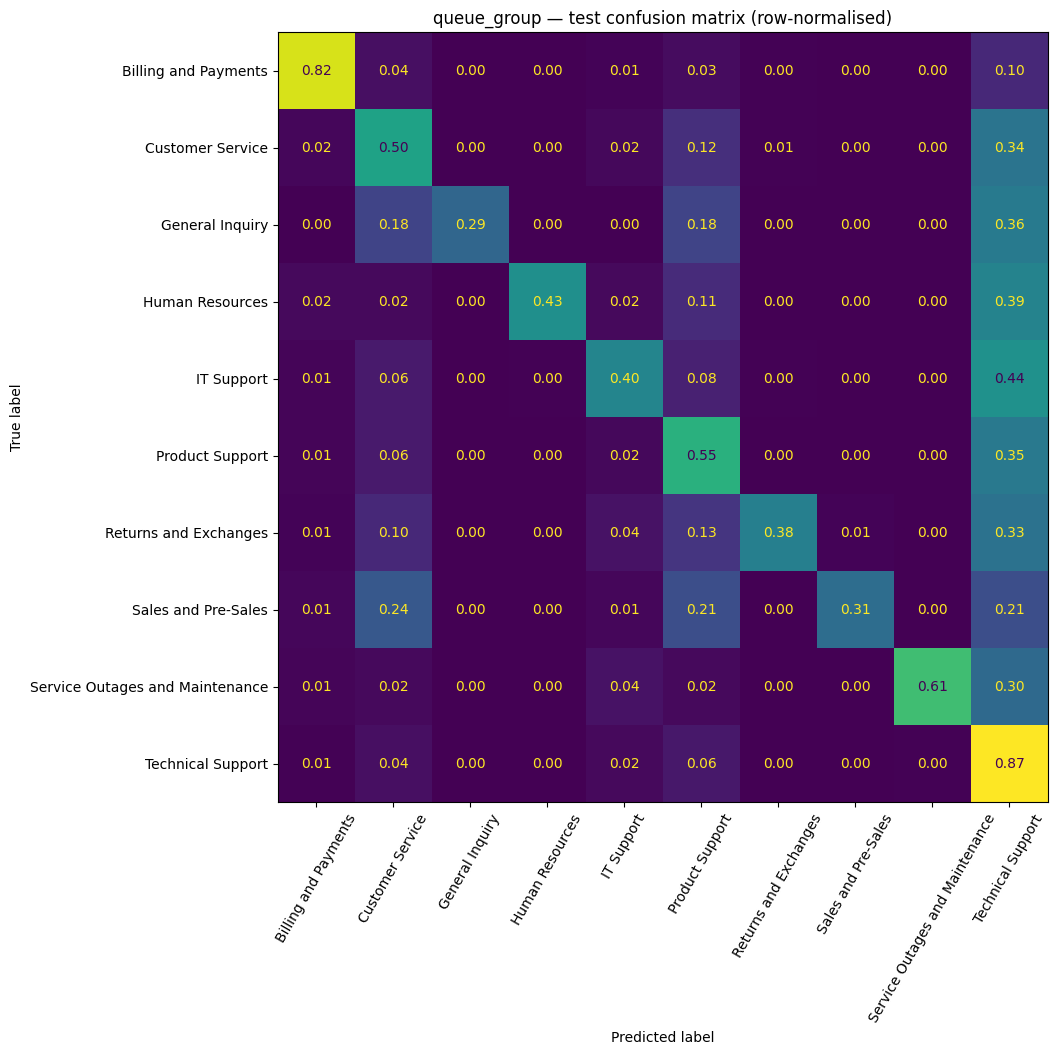

PRIORITY  (linear_svm, C=4.0)
              precision    recall  f1-score   support

        high       0.68      0.70      0.69       908
         low       0.84      0.24      0.37       465
      medium       0.60      0.78      0.68       966

    accuracy                           0.64      2339
   macro avg       0.71      0.57      0.58      2339
weighted avg       0.68      0.64      0.62      2339

majority baseline: acc=0.413, macro-F1=0.195


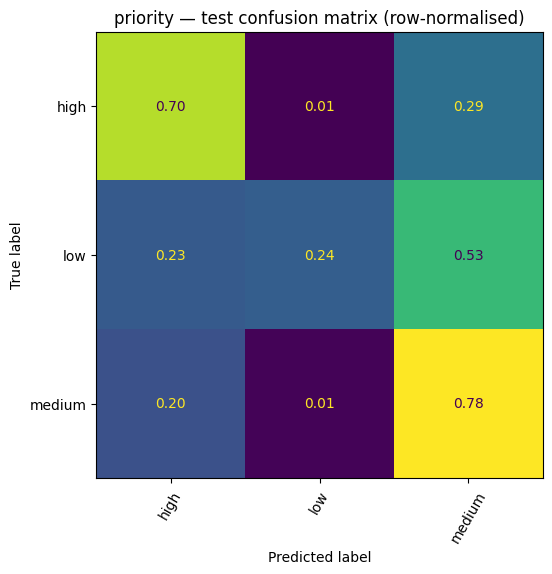

TYPE  (linear_svm, C=4.0)
              precision    recall  f1-score   support

      Change       0.98      0.94      0.96       267
    Incident       0.82      0.93      0.87       915
     Problem       0.79      0.59      0.67       451
     Request       0.98      0.99      0.99       706

    accuracy                           0.88      2339
   macro avg       0.89      0.86      0.87      2339
weighted avg       0.88      0.88      0.88      2339

majority baseline: acc=0.391, macro-F1=0.141


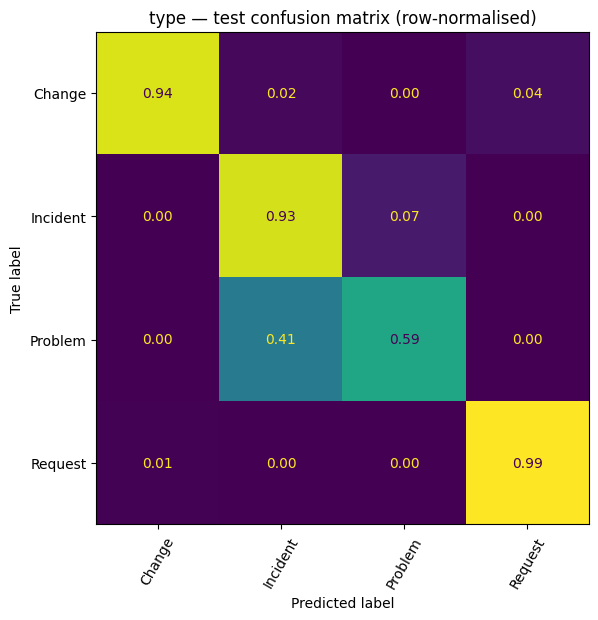

In [6]:
cls_metrics, LABELS = {}, {}
os.makedirs(sg.CLASSIFIER_DIR, exist_ok=True)
for target in TARGETS:
    tr, te = train_df.dropna(subset=[target]), test_df.dropna(subset=[target])
    best = selection[target]
    base_clf = CANDIDATES[best["model"]](best["C"])
    clf = CalibratedClassifierCV(base_clf, cv=3) if best["model"] == "linear_svm" else base_clf
    pipe = Pipeline([("features", features()), ("clf", clf)]).fit(text(tr), tr[target])
    pred = pipe.predict(text(te))

    p, r, f, _ = precision_recall_fscore_support(te[target], pred, average="macro", zero_division=0)
    m = {"model": best["model"], "C": best["C"], "val_macro_f1": best["val_macro_f1"],
         "test_n": len(te), "accuracy": accuracy_score(te[target], pred),
         "macro_precision": p, "macro_recall": r, "macro_f1": f,
         "weighted_f1": f1_score(te[target], pred, average="weighted"),
         "per_class": classification_report(te[target], pred, output_dict=True, zero_division=0)}
    for name, strat in [("majority", "most_frequent"), ("stratified_random", "stratified")]:
        d = DummyClassifier(strategy=strat, random_state=sg.SEED).fit(text(tr), tr[target]).predict(text(te))
        m[f"baseline_{name}"] = {"accuracy": accuracy_score(te[target], d), "macro_f1": f1_score(te[target], d, average="macro")}

    labels = list(pipe.classes_)
    cm = confusion_matrix(te[target], pred, labels=labels)
    m["labels"], m["confusion_matrix"] = labels, cm.tolist()
    cls_metrics[target] = m
    LABELS[target] = labels

    print("=" * 90, f"\n{target.upper()}  ({best['model']}, C={best['C']})")
    print(classification_report(te[target], pred, zero_division=0))
    print(f"majority baseline: acc={m['baseline_majority']['accuracy']:.3f}, macro-F1={m['baseline_majority']['macro_f1']:.3f}")

    fig, ax = plt.subplots(figsize=(min(4 + len(labels) * 0.6, 14),) * 2)
    ConfusionMatrixDisplay(confusion_matrix(te[target], pred, labels=labels, normalize="true"), display_labels=labels).plot(
        ax=ax, xticks_rotation=60, values_format=".2f", colorbar=False)
    ax.set_title(f"{target} — test confusion matrix (row-normalised)")
    plt.savefig(os.path.join(sg.PLOTS_DIR, f"cm_{target}.png"), dpi=130, bbox_inches="tight"); plt.show()

    joblib.dump(pipe, os.path.join(sg.CLASSIFIER_DIR, f"{target}.joblib"))

## 3. Summary table

In [7]:
summary = pd.DataFrame({t: {k: cls_metrics[t][k] for k in ["model", "C", "test_n", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]}
                        | {"majority_acc": cls_metrics[t]["baseline_majority"]["accuracy"],
                           "majority_macro_f1": cls_metrics[t]["baseline_majority"]["macro_f1"]}
                        for t in TARGETS}).T
display(summary)

,model,C,test_n,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,majority_acc,majority_macro_f1
queue_group,linear_svm,4.0,2339,0.619923,0.80671,0.51678,0.5932,0.610961,0.279179,0.04365
priority,linear_svm,4.0,2339,0.643437,0.705877,0.57496,0.580456,0.62186,0.412997,0.194856
type,linear_svm,4.0,2339,0.881146,0.892273,0.85972,0.871109,0.876346,0.391193,0.140596


## 4. Sentiment — *inferred*, not evaluated
The dataset has **no sentiment labels**, so we cannot train or measure a sentiment classifier on it and
we do **not** report accuracy. Instead we apply a pretrained 3-class model
(`cardiffnlp/twitter-roberta-base-sentiment-latest`: negative / neutral / positive) as an *auxiliary
signal*. Below we only describe what it predicts on a test sample; this is exploratory, not ground truth.

In [8]:
from transformers import pipeline
SENT_MODEL = "cardiffnlp/twitter-roberta-base-sentiment-latest"
sent = pipeline("sentiment-analysis", model=SENT_MODEL, device=0 if sg.get_device() == "cuda" else -1)
sample = test_df.sample(min(500, len(test_df)), random_state=sg.SEED)
preds = sent(text(sample), truncation=True, max_length=512, batch_size=32)
sample["sentiment"] = [p["label"].lower() for p in preds]
dist = sample.sentiment.value_counts(normalize=True).round(3)
display(dist.to_frame("share of sampled test tickets"))
print("Inferred sentiment by priority (row %, exploratory only):")
display((pd.crosstab(sample.priority, sample.sentiment, normalize="index") * 100).round(1))
cls_metrics["sentiment_inferred"] = {"model": SENT_MODEL, "n_sampled": len(sample), "distribution": dist.to_dict(),
                                     "note": "Pretrained model applied without ground-truth labels; not evaluated."}

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

,share of sampled test tickets
sentiment,
negative,0.548
neutral,0.280
positive,0.172


Inferred sentiment by priority (row %, exploratory only):


sentiment,negative,neutral,positive
priority,,,
high,64.7,25.7,9.6
low,50.5,28.4,21.1
medium,48.2,29.8,22.0


## 5. Save classifiers and metrics
`models/classifiers/` holds one scikit-learn pipeline per target (`.joblib`) and `meta.json`.

⚠️ joblib files should be loaded with the **same scikit-learn version** they were saved with — it is
recorded in `meta.json`; install that version in the Mac backend environment.

In [9]:
meta = {"targets": TARGETS, "labels": LABELS, "text_input": "subject + ' . ' + body",
        "sklearn_version": sklearn.__version__, "selection": selection,
        "sentiment_model": SENT_MODEL}
sg.save_json(meta, os.path.join(sg.CLASSIFIER_DIR, "meta.json"))
sg.save_json(cls_metrics, os.path.join(sg.RESULTS_DIR, "cls_metrics.json"))

# sanity check: reload and predict one ticket
demo = {"subject": "Refund not received", "body": "I requested a refund two weeks ago and still have not received it."}
for t in TARGETS:
    pipe = joblib.load(os.path.join(sg.CLASSIFIER_DIR, f"{t}.joblib"))
    proba = pipe.predict_proba([demo["subject"] + " . " + demo["body"]])[0]
    print(f"{t:12s} → {pipe.classes_[proba.argmax()]}  ({proba.max():.2f})")
print("\nsaved:", sorted(os.listdir(sg.CLASSIFIER_DIR)))

queue_group  → Product Support  (0.27)
priority     → medium  (0.44)
type         → Problem  (0.83)

saved: ['meta.json', 'priority.joblib', 'queue_group.joblib', 'type.joblib']


**Interpretation tips for the report:** compare macro-F1 against the majority baseline. On a synthetic
dataset, priority may be only weakly predictable from text — if so, say so; it is a valid finding.

➡️ **Next:** `06_model_comparison.ipynb` — side-by-side comparison (optional Gemini) and model export.